## Step 1: Worked example from scratch in NumPy

A 2-2-1 network: two inputs, a hidden layer of two sigmoid units, and one sigmoid output unit. 


In [5]:
import numpy as np

sigma = lambda t: 1 / (1 + np.exp(-t))

x  = np.array([0.5, -1.0])
y = 1.0
W1 = np.array([[0.4, -0.2], [0.1, 0.6]])
b1 = np.array([0.1, -0.1])
W2 = np.array([[0.3, -0.5]])         
b2 = np.array([0.2])

# forward 
a = W1 @ x + b1
h = sigma(a)
z = W2 @ h + b2
yhat = sigma(z)
L = 0.5 * (yhat - y) ** 2

# reverse 
dz  = (yhat - y) * yhat * (1 - yhat)   
dW2 = np.outer(dz, h)                  
db2 = dz
dh  = W2.T @ dz                        
da  = dh * h * (1 - h)                 
dW1 = np.outer(da, x)                  
db1 = da

print(f"yhat = {yhat}")
print(f"L = {L}")
print(f"dW1 = {dW1}")
print(f"db1 = {db1}")
print(f"dW2 = {dW2}")
print(f"db2 = {db2}")

yhat = [0.55360396]
L = [0.09963471]
dW1 = [[-0.00388871  0.00777742]
 [ 0.00621488 -0.01242977]]
db1 = [-0.00777742  0.01242977]
dW2 = [[-0.06866744 -0.03783735]]
db2 = [-0.11031634]


## Step 2: Same network in PyTorch

The same parameters and input are rebuilt as tensors with `requires_grad=True`.

In [ ]:
import torch

x  = torch.tensor([0.5, -1.0])
y = torch.tensor(1.0)
W1 = torch.tensor([[0.4, -0.2], [0.1, 0.6]], requires_grad=True)
b1 = torch.tensor([0.1, -0.1],               requires_grad=True)
W2 = torch.tensor([[0.3, -0.5]],             requires_grad=True)
b2 = torch.tensor([0.2],                     requires_grad=True)

# forward
a = W1 @ x + b1
h = torch.sigmoid(a)
z = W2 @ h + b2
yhat = torch.sigmoid(z)
L = 0.5 * (yhat - y) ** 2
L = L.squeeze()          # make it a scalar so backward() works cleanly

L.backward()             # the backward sweep

print(f"yhat = {yhat.item()}")
print(f"L = {L.item()}")
print(f"dW1 = {W1.grad}")
print(f"db1 = {b1.grad}")
print(f"dW2 = {W2.grad}")
print(f"db2 = {b2.grad}")

yhat = 0.5536039471626282
L = 0.09963471442461014
dW1 = tensor([[-0.0039,  0.0078],
        [ 0.0062, -0.0124]])
db1 = tensor([-0.0078,  0.0124])
dW2 = tensor([[-0.0687, -0.0378]])
db2 = tensor([-0.1103])


## Step 3: Finite-difference gradient check

This cell checks the backprop gradients numerically. For each of the nine parameters it:

1. nudges the parameter by `+eps` and `-eps` (`eps = 1e-5`) and recomputes the loss,
2. estimates the gradient with the central difference `(L+ - L-) / (2 eps)`,
3. restores the parameter and compares the estimate with the backprop gradient.

A tiny `diff` (around 1e-12 or smaller) means the analytic gradients are correct.

In [ ]:
W1 = np.array([[0.4, -0.2], [0.1, 0.6]])
b1 = np.array([0.1, -0.1])
W2 = np.array([[0.3, -0.5]])
b2 = np.array([0.2])
x  = np.array([0.5, -1.0])
y  = 1.0


def loss(W1, b1, W2, b2):
    a = W1 @ x + b1
    h = sigma(a)
    z = W2 @ h + b2
    yhat = sigma(z)
    return (0.5 * (yhat - y) ** 2).item()

params = [W1, b1, W2, b2]
grads  = [dW1, db1, dW2, db2]
names  = ["W1", "b1", "W2", "b2"]
eps = 1e-5

for name, p, g in zip(names, params, grads):
    for idx in np.ndindex(p.shape):         
        old = p[idx]
        p[idx] = old + eps;  Lp = loss(W1, b1, W2, b2)
        p[idx] = old - eps;  Lm = loss(W1, b1, W2, b2)
        p[idx] = old 
        fd = (Lp - Lm) / (2 * eps)
        print(f"{name}{idx}: fd={fd:.8f}  backprop={g[idx]:.8f}  diff={abs(fd-g[idx]):.2e}")

W1(0, 0): fd=-0.00388871  backprop=-0.00388871  diff=4.78e-15
W1(0, 1): fd=0.00777742  backprop=0.00777742  diff=9.57e-15
W1(1, 0): fd=0.00621488  backprop=0.00621488  diff=1.02e-12
W1(1, 1): fd=-0.01242977  backprop=-0.01242977  diff=7.38e-13
b1(0,): fd=-0.00777742  backprop=-0.00777742  diff=9.57e-15
b1(1,): fd=0.01242977  backprop=0.01242977  diff=7.38e-13
W2(0, 0): fd=-0.06866744  backprop=-0.06866744  diff=4.25e-13
W2(0, 1): fd=-0.03783735  backprop=-0.03783735  diff=5.34e-13
b2(0,): fd=-0.11031634  backprop=-0.11031634  diff=1.62e-12


## Step 4: Train with gradient descent and plot the loss

Plain gradient descent on the single training example. Each step runs the forward pass, records `L`, runs the backward pass, then updates every parameter with `p -= eta * grad` (`eta = 1.0`, 100 steps). The printed values are the loss at the first step, the second step and the last step. 

0.09963471079660575 0.08191317659551776 0.0018107746939455712


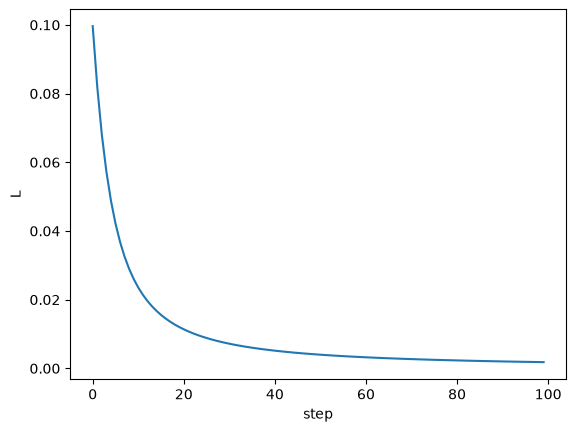

In [13]:
import numpy as np
import matplotlib.pyplot as plt

sigma = lambda t: 1 / (1 + np.exp(-t))

x  = np.array([0.5, -1.0]);  y = 1.0
W1 = np.array([[0.4, -0.2], [0.1, 0.6]]);  b1 = np.array([0.1, -0.1])
W2 = np.array([[0.3, -0.5]]);              b2 = np.array([0.2])

eta = 1.0
steps = 100
losses = []

for step in range(steps):
    # forward
    a = W1 @ x + b1
    h = sigma(a)
    z = W2 @ h + b2
    yhat = sigma(z)
    L = (0.5 * (yhat - y) ** 2).item()
    losses.append(L)

    # backward
    dz  = (yhat - y) * yhat * (1 - yhat)
    dW2 = np.outer(dz, h);  db2 = dz
    dh  = W2.T @ dz
    da  = dh * h * (1 - h)
    dW1 = np.outer(da, x);  db1 = da

    # update
    W1 -= eta * dW1;  b1 -= eta * db1
    W2 -= eta * dW2;  b2 -= eta * db2

print(losses[0], losses[1], losses[-1]) 
plt.plot(losses)
plt.xlabel("step"); plt.ylabel("L"); plt.show()

## Step 5: Compare hidden activations (sigmoid, tanh, ReLU)

The sigmoid output unit stays the same, and only the hidden activation changes. For each activation the cell runs one forward pass from the original starting weights, then computes the backward quantities `dz`, `dh` and `da = dh * f'(a)`. It prints `yhat`, `da` and `||da||`, the L2 norm of `dL/da`.

The derivatives are:
- sigmoid: `h(1 - h)`, which is at most 0.25
- tanh: `1 - h^2`, which is at most 1
- ReLU: 1 where `a > 0`, otherwise 0

In [ ]:
import numpy as np

sigma = lambda t: 1 / (1 + np.exp(-t))

acts = {
    "sigmoid": (sigma,                      lambda a, h: h * (1 - h)),
    "tanh":    (np.tanh,                    lambda a, h: 1 - h**2),
    "relu":    (lambda a: np.maximum(0, a), lambda a, h: (a > 0).astype(float)),
}

x  = np.array([0.5, -1.0]);  y = 1.0
W1 = np.array([[0.4, -0.2], [0.1, 0.6]]);  b1 = np.array([0.1, -0.1])
W2 = np.array([[0.3, -0.5]]);              b2 = np.array([0.2])

for name, (f, fprime) in acts.items():
    a = W1 @ x + b1
    h = f(a)
    z = W2 @ h + b2
    yhat = sigma(z)

    dz = (yhat - y) * yhat * (1 - yhat)
    dh = W2.T @ dz                         
    da = dh * fprime(a, h)                   
    print(f"{name:8s} yhat={yhat.item():.4f}  da={da}  ||da||={np.linalg.norm(da):.5f}")

sigmoid  yhat=0.5536  da=[-0.00777742  0.01242977]  ||da||=0.01466
tanh     yhat=0.6512  da=[-0.01868941  0.02666332]  ||da||=0.03256
relu     yhat=0.5866  da=[-0.03007325  0.        ]  ||da||=0.03007


## **Result:** 

Tanh gives the largest norm (about 0.0326), then ReLU (0.0301), then sigmoid (0.0147).
- **Sigmoid:** its derivative is at most 0.25, so it shrinks the gradient the most.
- **Tanh:** It is larger because its derivative can reach 1 (here 0.79 and 0.67), so much less gradient is lost at each hidden unit.
- **ReLU:** the first unit passes the gradient at full strength (derivative 1). The second unit has `a < 0`, so its derivative is 0 and it passes no gradient. That zero costs ReLU the top spot here, even though its derivative is 1 where it is active.